# How `restore.py` works, and why

`restore.py` repairs the artefacts of the NextBrain ex-vivo reconstructions **without deep learning**,
using geometry and a few anatomical rules. This notebook runs every step of the pipeline on a real
case, shows what each one does, and explains **why** it is done that way.

**Contents**
1. The problem: what the artefacts look like and why sulci make it hard
2. Label classes: why the method needs to know which labels are cortex
3. Background runs: the basic measurement
4. Step 1, gap planes: finding the block boundaries
5. Step 2, block shifts: undoing the misalignment between blocks
6. Step 3, gap filling
7. Step 4, cracks
8. Step 5, enclosed holes
9. The full pipeline in one call, and its outputs
10. Parameters: what each one controls
11. L1 inputs, validation and limitations

To keep the notebook fast, case-4 is downsampled from 0.2 mm to **0.4 mm** (every second voxel).
The method is identical at 0.2 mm; only the voxel counts change.

In [1]:
import os, sys, time, json
import numpy as np
import nibabel as nib
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from scipy import ndimage as ndi

sys.path.insert(0, os.path.abspath("."))
import restore as R

%matplotlib inline
plt.rcParams["figure.dpi"] = 90

CASE, DS = 4, 2
img = nib.load(f"../data/inputs/recon_holes_0.2mm/case-{CASE}.nii.gz")
seg = np.ascontiguousarray(np.asarray(img.dataobj)[::DS, ::DS, ::DS]).astype(np.int32)
zooms = tuple(round(float(z) * DS, 4) for z in img.header.get_zooms()[:3])
affine = img.affine.copy(); affine[:3, :3] *= DS
print(f"shape {seg.shape}, voxel {zooms} mm, {len(np.unique(seg)) - 1} labels")

shape (234, 489, 365), voxel (0.4, 0.4, 0.4) mm, 296 labels


In [2]:
# ---- display helpers -------------------------------------------------------------
L1_NAMES = ["Background", "Brainstem", "CSF / ventricles", "Cerebellar GM", "Cerebellar WM",
            "Cerebral GM", "Cerebral WM", "Deep GM", "Other"]
L1_COLORS = ["#000000", "#e6550d", "#3182bd", "#a1d99b", "#31a354", "#fdd0a2", "#f7f7f7", "#9e65c9", "#e7298a"]
CMAP = ListedColormap(L1_COLORS)
SAG, COR, AXI = 0, 1, 2           # array axes: 0 = left-right, 1 = posterior-anterior, 2 = inferior-superior

def sl(vol, axis, idx, crop=None):
    s = np.take(vol, idx, axis=axis).T          # rows = second remaining axis, shown bottom-up
    return s if crop is None else s[crop]

def show_l1(ax, l1vol, axis, idx, crop=None, title=None):
    ax.imshow(sl(l1vol, axis, idx, crop), cmap=CMAP, vmin=-0.5, vmax=8.5, origin="lower", interpolation="nearest")
    ax.set_xticks([]); ax.set_yticks([])
    if title: ax.set_title(title, fontsize=10)

def overlay(ax, mask, axis, idx, color, crop=None, alpha=1.0):
    m = sl(mask, axis, idx, crop)
    rgba = np.zeros(m.shape + (4,)); rgba[m] = list(plt.matplotlib.colors.to_rgba(color, alpha))
    ax.imshow(rgba, origin="lower", interpolation="nearest")

def crop_at(rc, cc, half):
    return (slice(max(rc - half, 0), rc + half), slice(max(cc - half, 0), cc + half))

def legend(fig, y=0.0):
    from matplotlib.patches import Patch
    fig.legend(handles=[Patch(fc=c, ec="grey", label=n) for n, c in zip(L1_NAMES[1:], L1_COLORS[1:])],
               loc="lower center", ncol=8, fontsize=8, frameon=False, bbox_to_anchor=(0.5, y))

## 1. The problem

NextBrain hemispheres are cut into ~1 cm **tissue blocks** (near-coronal slabs). Each block is sectioned
for histology, segmented, and the blocks are stacked back together in 3D. This leaves four kinds of
artefact in the label map:

| artefact | cause | what it looks like |
|---|---|---|
| **block gaps** | tissue lost at the cut between two blocks | thin (0.4–2 mm) background slabs every ~11–13 mm, a few degrees from coronal, often crossing only part of the brain |
| **block steps** | the blocks are not perfectly aligned | anatomy "jumps" sideways at a block boundary |
| **cracks** | torn or missing sections inside a block | short thin background cracks |
| **holes** | tissue damage | enclosed background cavities |

The core difficulty: **sulci are also thin background sheets**. Any rule of the type "fill thin
background" also closes the sulci and destroys the cortical folding. Every step below is designed
around this problem.

In [3]:
l1_tmp = None
fg = seg > 0
ext = [np.nonzero(fg.any(axis=tuple(a for a in range(3) if a != ax)))[0] for ax in range(3)]
MID = [int(e.mean()) for e in ext]
X2 = int(np.percentile(ext[0], 30))
print("slice indices used below: sagittal", MID[0], "and", X2, "| coronal", MID[1], "| axial", MID[2])

slice indices used below: sagittal 114 and 73 | coronal 245 | axial 170


## 2. Label classes: why the method needs to know which labels are cortex

The input has ~300 NextBrain labels, but the rules only need to know the **tissue class** of a label.
The key question is always the same: *is this background lined by cortex?*

- Background lined by **cortex** (cerebral or cerebellar GM) is probably a **sulcus**, which is real anatomy.
- Background lined by **white matter, deep GM, brainstem…** is probably an **artefact**: sulci never
  cut through white matter, but block gaps do.

The classes are the L1 level (9 classes), built with the same code as the `*_L1` files
(`wp1/create_merged_segmentations/merge_labels.py`, NextBrain ontology + `mapping_l1.json`). Raw labels
1, 2 and 3 are not in the ontology, so they are added by hand (`EXTRA_L1`: 1→Brainstem, 2→CSF,
3→Cerebral GM). The result is a lookup table `lut[label] → L1 class`.

Cortex classes: `CORTEX_L1 = (3, 5)` (cerebellar GM and cerebral GM).

cortex classes: ['Cerebellar GM', 'Cerebral GM']
voxels per L1 class: {'Brainstem': 144910, 'CSF / ventricles': 120701, 'Cerebellar GM': 922774, 'Cerebellar WM': 262373, 'Cerebral GM': 4711243, 'Cerebral WM': 2983025, 'Deep GM': 335630, 'Other': 88}


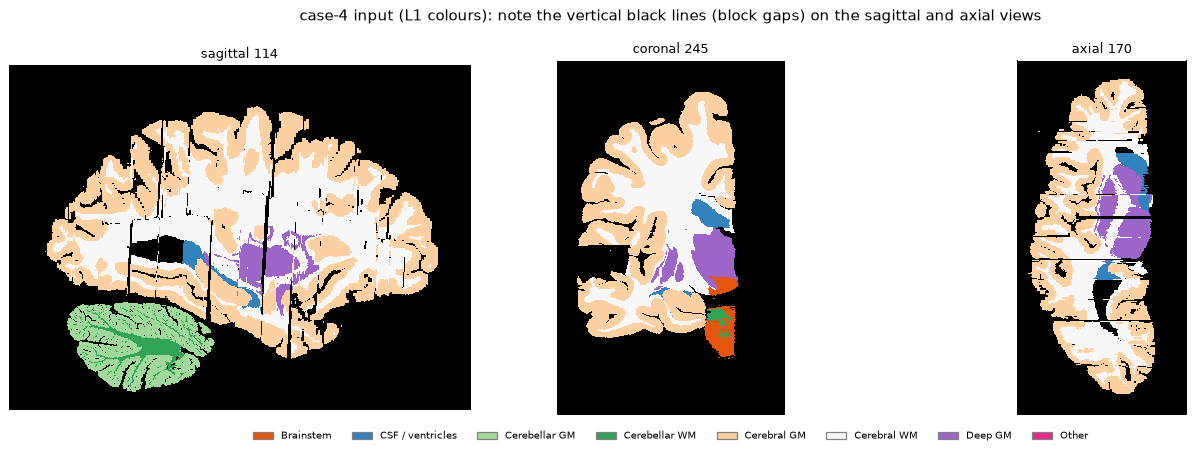

In [4]:
lut = R.load_l1_lut(int(seg.max()))
l1 = lut[seg]
print("cortex classes:", [L1_NAMES[c] for c in R.CORTEX_L1])
print("voxels per L1 class:", {L1_NAMES[c]: int(n) for c, n in enumerate(np.bincount(l1.ravel(), minlength=9)) if c})

fig, axs = plt.subplots(1, 3, figsize=(15, 5))
show_l1(axs[0], l1, SAG, MID[0], title=f"sagittal {MID[0]}")
show_l1(axs[1], l1, COR, MID[1], title=f"coronal {MID[1]}")
show_l1(axs[2], l1, AXI, MID[2], title=f"axial {MID[2]}")
legend(fig); plt.suptitle(f"case-{CASE} input (L1 colours): note the vertical black lines (block gaps) on the sagittal and axial views")
plt.tight_layout(rect=(0, 0.05, 1, 1)); plt.show()

## 3. Background runs: the basic measurement

Almost every step uses one measurement: **runs of background along an axis**. For each background
voxel, walk along the axis in both directions until you hit tissue. That gives:
- the **run length** (how thick the background is along that axis);
- whether the run is **bounded** (tissue on both sides, so it's inside the brain and not the outside);
- the **labels at both ends** of the run.

`bg_runs(seg, axis)` computes, for every voxel, the index of the previous and next tissue voxel with two
cumulative max/min passes, so it is fast even on 600 M voxels.

Block gaps are cut along the A-P axis (axis 1, found automatically from the affine by
`slicing_axis`), so a gap shows up as **short bounded runs along A-P**. But sulci that run roughly
coronally give exactly the same kind of short runs. Below, short runs (≤ 2.4 mm) are coloured by
what bounds them:
- **red**: non-cortical tissue at both ends (typical of a gap crossing white matter);
- **cyan**: cortex at one or both ends (typical of a sulcus).

slicing axis = 1 | short-run voxels: 730,594 (139,848 non-cortical, 590,746 cortical)


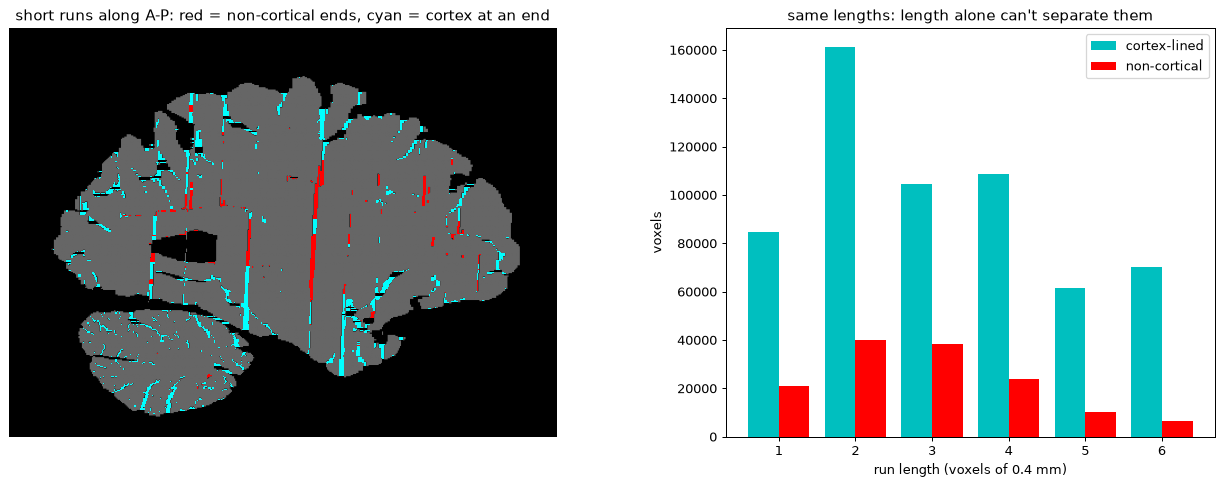

In [5]:
axis = R.slicing_axis(affine)
L = seg.shape[axis]
max_len = int(round(2.4 / zooms[axis]))
prev, nxt = R.bg_runs(seg, axis)
short = (seg == 0) & (prev >= 0) & (nxt < L) & (nxt - prev - 1 <= max_len)
cls_prev = lut[np.take_along_axis(seg, np.clip(prev, 0, L - 1), axis)]
cls_next = lut[np.take_along_axis(seg, np.clip(nxt, 0, L - 1), axis)]
noncx_run = short & ~np.isin(cls_prev, R.CORTEX_L1) & ~np.isin(cls_next, R.CORTEX_L1)
cx_run = short & ~noncx_run
run_len = np.where(short, nxt - prev - 1, 0)
print(f"slicing axis = {axis} | short-run voxels: {short.sum():,} "
      f"({noncx_run.sum():,} non-cortical, {cx_run.sum():,} cortical)")

fig, axs = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw=dict(width_ratios=[1.6, 1]))
axs[0].imshow(sl(seg > 0, SAG, MID[0]), cmap="gray", vmin=0, vmax=2.5, origin="lower")
overlay(axs[0], cx_run, SAG, MID[0], "cyan"); overlay(axs[0], noncx_run, SAG, MID[0], "red")
axs[0].set_title("short runs along A-P: red = non-cortical ends, cyan = cortex at an end"); axs[0].axis("off")
bins = np.arange(1, max_len + 2) - 0.5
axs[1].hist([run_len[cx_run], run_len[noncx_run]], bins=bins, label=["cortex-lined", "non-cortical"], color=["c", "r"])
axs[1].set_xlabel(f"run length (voxels of {zooms[axis]} mm)"); axs[1].set_ylabel("voxels"); axs[1].legend()
axs[1].set_title("same lengths: length alone can't separate them")
plt.tight_layout(); plt.show()

**What this shows.** The red runs line up on straight, regularly spaced lines: the block gaps.
The cyan runs are everywhere along the cortex: sulci. Both have the same lengths, so **run length is
not enough**. Two extra pieces of information separate them:
1. **Geometry.** Gap runs lie on a few **planes** (one per block boundary). Sulci are curved and scattered.
2. **What bounds them.** Gap runs often cross white matter; sulci are always lined by cortex.

Step 1 uses both.

## 4. Step 1: finding the gap planes (`detect_planes`)

### 4a. The global orientation of the cuts (`estimate_normal`)
Take the **midpoint** of every short bounded run. If we project all midpoints onto the right direction
(the normal of the cutting planes), the midpoints of gap runs pile up at a few positions and make
**sharp peaks**; sulcus midpoints make a smooth background.

The blocks are cut a few degrees off coronal, and the exact tilt is unknown. So the normal is found by a
**grid search** over two tilt angles (pitch and yaw, ±25°): for each candidate normal, histogram the
projected midpoints and measure how *spiky* the histogram is:

$$\text{spikiness} = \frac{\mathrm{RMS}\big(\max(h - \mathrm{median\_filter}(h),\,0)\big)}{\mathrm{mean}(h)}$$

i.e. how much the histogram rises above its own smooth baseline. A coarse 2° grid is refined with a
0.5° grid around the best value.

**Why a grid search and not, e.g., PCA or a Hough transform?** There are only two angles, the score
is cheap (one `bincount`), and the grid is robust to the huge number of sulcus midpoints
that would bias any least-squares fit.

314,071 run midpoints | best normal: pitch -2.5 deg, yaw 0.0 deg, spikiness 1.41


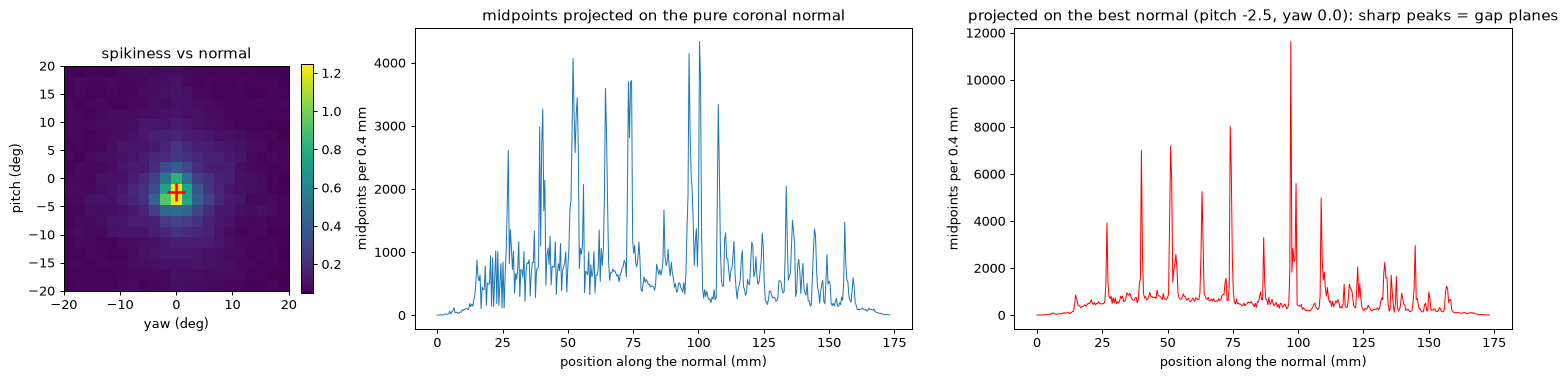

In [6]:
mid, length, ip, inx = R.short_run_points(seg, axis, max_len)
pitch, yaw, sc = R.estimate_normal(mid, axis, zooms)
print(f"{len(mid):,} run midpoints | best normal: pitch {pitch:.1f} deg, yaw {yaw:.1f} deg, spikiness {sc:.2f}")

# score landscape (coarse, on a subsample) to show the optimum is well defined
rng = np.random.default_rng(0)
sub = mid[rng.choice(len(mid), min(len(mid), 150_000), replace=False)] * np.asarray(zooms, np.float32)
angles = np.arange(-20, 20.1, 2.0)
win = max(3, int(round(6.0 / 0.4)) | 1)
def score(p, y):
    t = sub @ R.normal_from_angles(p, y, axis).astype(np.float32)
    return R.spikiness(np.bincount(((t - t.min()) / 0.4).astype(np.int64)).astype(float), win)
S = np.array([[score(p, y) for y in angles] for p in angles])

def proj_hist(p, y):
    t = (mid * np.asarray(zooms, np.float32)) @ R.normal_from_angles(p, y, axis).astype(np.float32)
    return np.bincount(((t - t.min()) / 0.4).astype(np.int64))

fig, axs = plt.subplots(1, 3, figsize=(17, 4.3), gridspec_kw=dict(width_ratios=[1, 2, 2]))
im = axs[0].imshow(S, extent=[angles[0], angles[-1], angles[0], angles[-1]], origin="lower", cmap="viridis")
axs[0].plot(yaw, pitch, "r+", ms=14, mew=2); axs[0].set_xlabel("yaw (deg)"); axs[0].set_ylabel("pitch (deg)")
axs[0].set_title("spikiness vs normal"); plt.colorbar(im, ax=axs[0], fraction=0.046)
axs[1].plot(np.arange(len(h := proj_hist(0, 0))) * 0.4, h, lw=0.8); axs[1].set_title("midpoints projected on the pure coronal normal")
axs[2].plot(np.arange(len(h := proj_hist(pitch, yaw))) * 0.4, h, lw=0.8, c="r")
axs[2].set_title(f"projected on the best normal (pitch {pitch:.1f}, yaw {yaw:.1f}): sharp peaks = gap planes")
for a in axs[1:]: a.set_xlabel("position along the normal (mm)"); a.set_ylabel("midpoints per 0.4 mm")
plt.tight_layout(); plt.show()

### 4b. One candidate per peak
Along the best normal, the histogram is smoothed (3 bins) and a **running median** over 8 mm is used as
the baseline. A position is a **candidate plane** if it rises above the baseline by more than
`peak_z` (= 4) robust standard deviations (MAD), and is the local maximum within `min_sep_mm` (4 mm).

**Why a median baseline?** The density of sulci changes slowly through the brain (more cortex in some
regions), so a fixed threshold would either miss gaps in sparse regions or accept sulci in dense
ones. The median follows that slow trend but ignores narrow peaks.

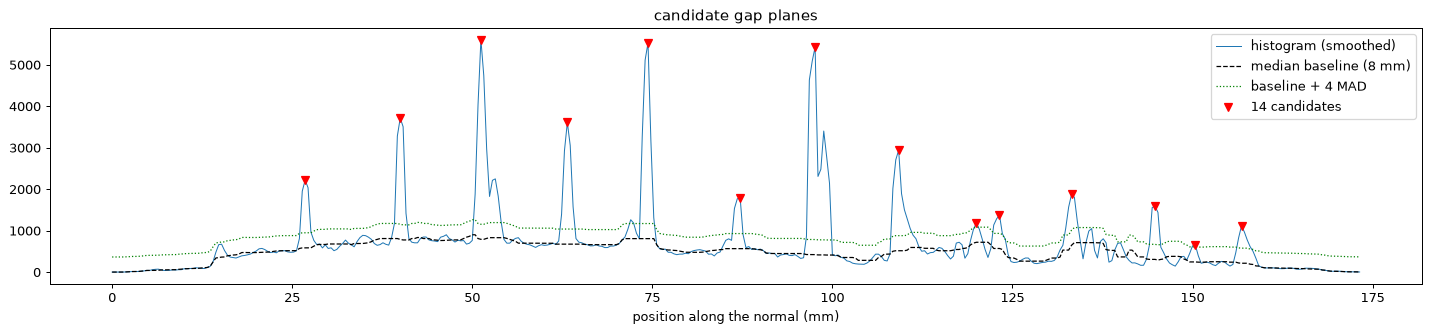

In [7]:
n = R.normal_from_angles(pitch, yaw, axis)
t = (mid * np.asarray(zooms, np.float32)) @ n.astype(np.float32)
bin_mm = zooms[axis]
b = ((t - t.min()) / bin_mm).astype(np.int64)
h = np.bincount(b).astype(float)
hs = ndi.uniform_filter1d(h, 3)
base = ndi.median_filter(hs, size=int(round(8.0 / bin_mm)) | 1, mode="nearest")
resid = hs - base
mad = np.median(np.abs(resid - np.median(resid))) * 1.4826
cand = np.flatnonzero((resid > 4 * mad) & (resid == ndi.maximum_filter1d(resid, int(round(4.0 / bin_mm)) | 1)))
pos = np.arange(len(h)) * bin_mm

plt.figure(figsize=(16, 3.8))
plt.plot(pos, hs, lw=0.8, label="histogram (smoothed)")
plt.plot(pos, base, "k--", lw=1, label="median baseline (8 mm)")
plt.plot(pos, base + 4 * mad, "g:", lw=1, label="baseline + 4 MAD")
plt.plot(pos[cand], hs[cand], "rv", label=f"{len(cand)} candidates")
plt.xlabel("position along the normal (mm)"); plt.legend(); plt.title("candidate gap planes")
plt.tight_layout(); plt.show()

### 4c. A robust plane per candidate (`fit_plane_ransac`)
For each candidate, take the midpoints within ±2 mm of the peak and fit a plane
`j = a·u + b·v + c` (j = A-P index, u, v = the two other axes) with **RANSAC**:
random triplets of points propose a plane; the plane with most points within 1.5 voxels wins; it is
then refined by least squares on its inliers.

**Why RANSAC and a separate plane per gap?**
- Each block is cut separately, so neighbouring gaps are **not exactly parallel**. One shared normal
  would leave the gaps of tilted blocks partly unfilled. Each plane may deviate up to
  `max_dev_deg` (10°) from the global normal.
- Most midpoints near a peak are **sulci**, not gap (outliers). Least squares would be pulled by them,
  RANSAC ignores them.
- Gaps often cross **only part** of the brain (the blocks were not cut through the whole hemisphere),
  so the fit must work with a partial plane.

### 4d. Rejecting sulcus "planes" (the non-cortical test)
A peak can also come from many coronal-ish sulci lining up by chance. Two checks remove these:
- **coverage** ≥ `min_coverage` (2%): the plane's runs must cover at least 2% of the brain's projected area;
- **non-cortical fraction** ≥ `min_noncortex` (8%): at least 8% of the plane's runs must be bounded by
  non-cortical tissue at **both** ends.

**Why the second test?** A real gap cuts straight through the brain, so part of it crosses white
matter or deep GM. A sulcus never does. Without this test, on a **clean** FOMO segmentation (no gaps at all) the
method invented planes in sulcal regions and filled 26% of the sulci; with it, it filled less than 0.1%.
This is shown below on a clean FOMO volume.

In [8]:
planes, info = R.detect_planes(seg, zooms, axis, max_gap_mm=2.4, angle_max=25, min_coverage=0.02,
                               max_dev_deg=10.0, peak_z=4.0, lut=lut, min_noncortex=0.08, verbose=True)
print()
print(f"{'plane':>5} {'pos@centre':>10} {'coverage':>8} {'non-cortical':>12} {'width (vox)':>11} {'tilt from global (deg)':>22}")
for i, p in enumerate(planes):
    c = p["coef"]; o = [a for a in range(3) if a != axis]
    pc = c[0] * seg.shape[o[0]] / 2 + c[1] * seg.shape[o[1]] / 2 + c[2]
    tilt = np.degrees(np.arccos(min(1, abs(np.dot(p["normal"], n)))))
    print(f"{i:5d} {pc:10.1f} {p['coverage']:8.3f} {p['noncortex_frac']:12.2f} {p['width_vox']:11.1f} {tilt:22.1f}")

[19:34:00]   314,071 short background runs (<= 2.4 mm) along axis 1
[19:34:01]   global normal: pitch=-2.5 yaw=0.0 deg (spikiness 1.41)
[19:34:02]   14 gap planes (coverage / non-cortical runs): 0.14/0.20, 0.24/0.15, 0.37/0.24, 0.23/0.26, 0.37/0.38, 0.12/0.19, 0.43/0.46, 0.25/0.21, 0.08/0.25, 0.11/0.24, 0.16/0.28, 0.10/0.13, 0.05/0.23, 0.10/0.21

plane pos@centre coverage non-cortical width (vox) tilt from global (deg)
    0       96.1    0.142         0.20         1.0                    0.4
    1      128.8    0.238         0.15         3.0                    0.4
    2      157.2    0.368         0.24         2.0                    0.7
    3      187.1    0.233         0.26         2.0                    0.3
    4      214.6    0.368         0.38         3.0                    0.7
    5      244.7    0.124         0.19         1.0                    1.6
    6      273.1    0.435         0.46         2.0                    1.5
    7      303.4    0.247         0.21         2.0         

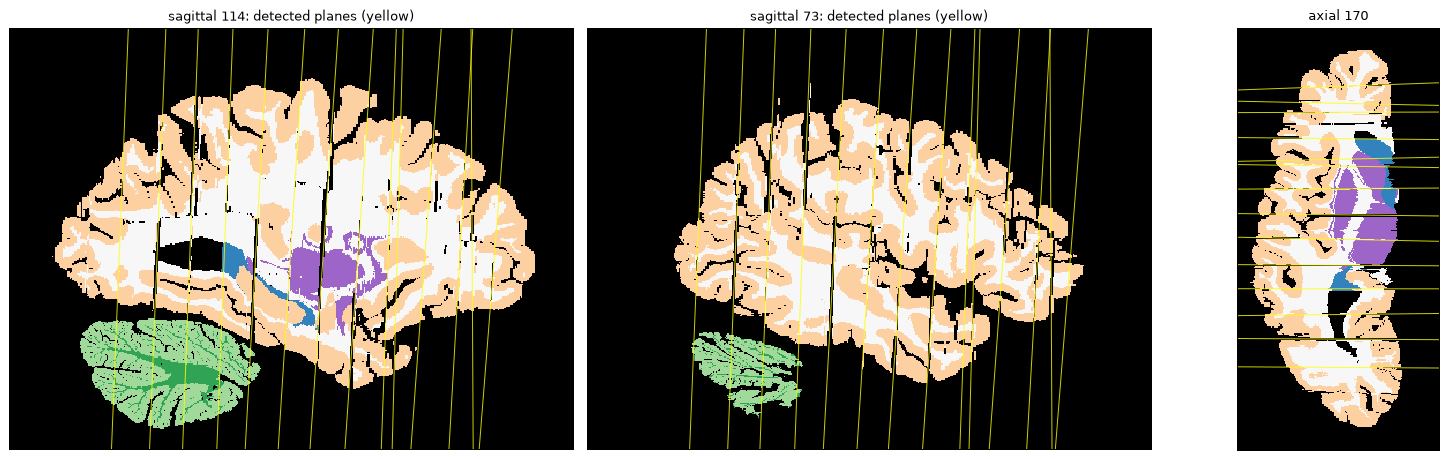

In [9]:
def draw_planes(ax, planes, view, idx, **kw):
    for p in planes:
        a, b_, c = p["coef"]                      # j = a*x + b*z + c   (axis 1 = j, u = axis 0, v = axis 2)
        if view == SAG:                            # image: cols = j (A-P), rows = z
            z = np.arange(seg.shape[2]); ax.plot(a * idx + b_ * z + c, z, **kw)
        elif view == AXI:                          # image: cols = x, rows = j
            x = np.arange(seg.shape[0]); ax.plot(x, a * x + b_ * idx + c, **kw)

fig, axs = plt.subplots(1, 3, figsize=(17, 5.2), gridspec_kw=dict(width_ratios=[1.3, 1.3, 0.8]))
for a_, x in zip(axs[:2], (MID[0], X2)):
    show_l1(a_, l1, SAG, x, title=f"sagittal {x}: detected planes (yellow)")
    draw_planes(a_, planes, SAG, x, c="yellow", lw=0.8, alpha=0.8)
    a_.set_xlim(0, seg.shape[1]); a_.set_ylim(0, seg.shape[2])
show_l1(axs[2], l1, AXI, MID[2], title=f"axial {MID[2]}")
draw_planes(axs[2], planes, AXI, MID[2], c="yellow", lw=0.8, alpha=0.8)
axs[2].set_xlim(0, seg.shape[0]); axs[2].set_ylim(0, seg.shape[1])
plt.tight_layout(); plt.show()

**Why the non-cortical test matters: a clean volume.** Below, plane detection is run on a clean FOMO
NextBrain segmentation (from an MRI, so it has **no block gaps at all**) with and without the test.
Every plane found there is a false positive that would close sulci.

In [10]:
fomo_path = "/home/Data/FOMO-300K/derivatives/nextbrain/PT017_HBN-SSI/sub-11/ses-03/anat/seg.left.nii.gz"
fimg = nib.load(fomo_path)
fseg = np.rint(np.asarray(fimg.dataobj)).astype(np.int32)
fz = tuple(float(z) for z in fimg.header.get_zooms()[:3])
flut = R.load_l1_lut(int(fseg.max()))
fax = R.slicing_axis(fimg.affine)
for mnc in (0.0, 0.08):
    pl, _ = R.detect_planes(fseg, fz, fax, lut=flut, min_noncortex=mnc, max_dev_deg=10.0, verbose=False)
    print(f"clean FOMO volume, min_noncortex={mnc}: {len(pl)} planes found "
          f"(non-cortical fractions: {[round(p['noncortex_frac'], 2) for p in pl]})")

clean FOMO volume, min_noncortex=0.0: 2 planes found (non-cortical fractions: [0.0, 0.05])
clean FOMO volume, min_noncortex=0.08: 0 planes found (non-cortical fractions: [])


## 5. Step 2: block shifts (`estimate_misalignments`, `solve_block_translations`, `apply_block_translations`)

The detected planes split the hemisphere into **blocks**. Planes closer than 4 mm are the same gap
fitted twice, so `boundary_planes` keeps only the one with the largest coverage.

**Measuring the step at one boundary.** Take two label "slices" that follow the plane, one just
before the gap (`a1`) and one just after (`b1`), each at `hw` voxels from the plane (half the gap
width + 1). Find the in-plane integer shift that best aligns them: **FFT cross-correlation** of the
one-hot masks of each tissue class (classes 1–7), summed over classes.

**Why subtract the natural drift?** Even without any misalignment, two slices 2–3 mm apart are not
identical: the anatomy changes (a gyrus moves, the ventricle curves). So the same measurement is made
**inside** each neighbouring block over the **same distance** (`a2→a1` and `b1→b2`). Their average is
the shift the anatomy would show anyway; only the excess is a block misalignment:

$$\text{mis} = d_{\text{across gap}} - \tfrac12\,(d_{\text{inside block before}} + d_{\text{inside block after}})$$

(An early version measured the drift over a longer distance and scaled it, which amplified noise
~3× and produced false 1-voxel shifts on clean volumes.)

**Why solve all blocks together?** Each boundary only gives a *relative* shift between two blocks.
The translations `T_k` of all blocks are found by least squares on `T_{k+1} − T_k ≈ −mis_k`, plus a
small penalty `λ·|T_k|²` (`shift_lambda` = 0.3). The penalty fixes the free global offset and stops
small errors from accumulating along the chain of blocks. Steps below `min_shift_mm` (0.4 mm) are
treated as zero: smaller values are within the measurement noise.

**Why integer voxels?** These are label maps. Sub-voxel translation would need interpolation, which
creates mixed or invalid labels. Each block is moved by whole voxels, so every label is copied, never
computed.

On this case the measured misalignments are small (0–2 voxels, i.e. up to 0.8 mm at 0.4 mm). The
"across gap" column already includes the natural drift; the last column is what remains after
subtracting it:

In [11]:
bplanes = R.boundary_planes(planes, seg.shape, axis, zooms)
mis = R.estimate_misalignments(l1, bplanes, zooms, axis, max_shift_mm=3.0, verbose=False)
T = R.solve_block_translations(mis, 0.3, 0.4 / zooms[axis])
print(f"{len(bplanes)} boundary planes -> {len(bplanes) + 1} blocks\n")
print(f"{'boundary':>8} {'across gap':>11} {'drift before':>12} {'drift after':>11} {'misalignment':>13}")
for i, m in enumerate(mis):
    print(f"{i:8d} {str(m['across']):>11} {str(m['drift_before']):>12} {str(m['drift_after']):>11} "
          f"{str([round(v, 1) for v in m['d_vox']]):>13}")
print("\nblock translations (voxels):", T.tolist())

12 boundary planes -> 13 blocks

boundary  across gap drift before drift after  misalignment
       0     [-1, 0]       [0, 0]      [0, 0]   [-1.0, 0.0]
       1     [0, -2]       [0, 0]    [-1, -2]   [0.5, -1.0]
       2     [0, -1]     [-1, -1]    [-1, -1]    [1.0, 0.0]
       3     [0, -1]      [0, -2]     [0, -3]    [0.0, 1.5]
       4    [-1, -2]       [0, 0]    [-1, -1]  [-0.5, -1.5]
       5     [0, -3]      [0, -1]     [0, -1]   [0.0, -2.0]
       6     [0, -1]      [0, -2]     [0, -1]    [0.0, 0.5]
       7     [0, -3]      [1, -2]    [-1, -1]   [0.0, -1.5]
       8     [-1, 1]       [0, 1]     [-1, 0]   [-0.5, 0.5]
       9     [0, -1]      [0, -1]     [0, -1]    [0.0, 0.0]
      10     [0, -1]       [0, 0]      [0, 0]   [0.0, -1.0]
      11      [0, 2]       [1, 1]      [0, 2]   [-0.5, 0.5]

block translations (voxels): [[0, 0], [0, 0], [1, 0], [0, 0], [0, -2], [0, -1], [0, 1], [0, 0], [0, 1], [0, 0], [0, 0], [0, 1], [0, 0]]


**Where `a1`, `b1`, `a2` and `b2` are.** The figure below shows one boundary from the side (sagittal
view, A-P axis horizontal). Each line is a 2D label slice seen edge-on; all four are parallel to the
fitted gap plane:

- `a1` (solid red): the last slice of tissue **before** the gap, `hw` voxels behind the plane;
- `b1` (solid green): the first slice of tissue **after** the gap, `hw` voxels ahead of the plane;
- `a2`, `b2` (dotted): slices deeper inside each block, a further `2·hw` away, so that `a2→a1` and
  `b1→b2` span the same distance as `a1→b1`.

"Before" and "after" always refer to the A-P axis: before = lower A-P index (posterior side of the
gap), after = higher index (anterior side). Comparing `a1` with `b1` gives the "across gap" column of
the table above; `a2` with `a1` gives "drift before"; `b1` with `b2` gives "drift after".

In [ ]:
from matplotlib.lines import Line2D
from matplotlib.patches import Patch, Rectangle

kb = len(bplanes) // 2 - 1                     # the boundary used in the known-shift example below
p_b = bplanes[kb]
jm_b = R.plane_map(p_b, seg.shape, axis)       # A-P position of the plane for every (x, z)
hw_b = int(np.ceil(p_b["width_p90_vox"] / 2)) + 1
wm = np.argwhere(lut[R.sample_along(seg, jm_b, -hw_b, axis)] == 6)
xs_b, zs_b = np.median(wm, axis=0).astype(int)  # a point of the cut face that lies in white matter
js_b = float(jm_b[xs_b, zs_b])
print(f"boundary {kb}: hw = {hw_b} vox -> a1 and b1 are {2 * hw_b} vox ({2 * hw_b * zooms[axis]:.1f} mm) apart")

SLICES = [("a2", -3 * hw_b, "red", ":"), ("a1", -hw_b, "red", "-"),
          ("b1", hw_b, "lime", "-"), ("b2", 3 * hw_b, "lime", ":")]
zz = np.arange(seg.shape[2])
HZ = 24                                         # half size of the zoom (voxels)
box = dict(fc="k", ec="none", alpha=0.6, pad=1.5)

fig, axs = plt.subplots(1, 2, figsize=(16, 6.2), gridspec_kw=dict(width_ratios=[1.35, 1]))

# left: whole sagittal slice, all boundary planes, block numbers
show_l1(axs[0], l1, SAG, xs_b, title=f"sagittal {xs_b}: boundary planes (yellow), boundary {kb} thicker")
edges = [np.zeros_like(zz, float)]
for i, q in enumerate(bplanes):
    edges.append(q["coef"][0] * xs_b + q["coef"][1] * zz + q["coef"][2])
    axs[0].plot(edges[-1], zz, c="yellow", lw=2.0 if i == kb else 0.7, alpha=0.9)
edges.append(np.full_like(zz, seg.shape[1], float))
for i in range(len(edges) - 1):                 # block i lies between boundary i-1 and boundary i
    if 0 < i < len(bplanes):
        axs[0].text((edges[i][-1] + edges[i + 1][-1]) / 2, seg.shape[2] - 6, str(i), color="w", fontsize=8, ha="center", va="top")
axs[0].add_patch(Rectangle((js_b - HZ, zs_b - HZ), 2 * HZ, 2 * HZ, fill=False, ec="cyan", lw=1.2))
axs[0].set_xlim(0, seg.shape[1]); axs[0].set_ylim(0, seg.shape[2])
axs[0].set_xlabel("posterior  ←  A-P axis (j)  →  anterior   |   white numbers = block index", fontsize=9)

# right: zoom on boundary kb with the four sampled slices
show_l1(axs[1], l1, SAG, xs_b, title=f"zoom on boundary {kb} (cyan box): the four sampled slices")
axs[1].plot(edges[kb + 1], zz, c="yellow", lw=1.2, ls="--")
for name, off, col, ls in SLICES:
    axs[1].plot(edges[kb + 1] + off, zz, c=col, lw=2, ls=ls)
    axs[1].text(js_b + off, zs_b + HZ - 1.5, name, color=col, fontsize=12, fontweight="bold", ha="center", va="top", bbox=box)
axs[1].set_xlim(js_b - HZ, js_b + HZ); axs[1].set_ylim(zs_b - HZ, zs_b + HZ)
axs[1].text(js_b - HZ + 1, zs_b - HZ + 1.5, f"block {kb} (before)", color="w", fontsize=10, ha="left", bbox=box)
axs[1].text(js_b + HZ - 1, zs_b - HZ + 1.5, f"block {kb + 1} (after)", color="w", fontsize=10, ha="right", bbox=box)

fig.legend(handles=[Line2D([], [], c="yellow", ls="--", label="fitted gap plane"),
                    Line2D([], [], c="red", lw=2, label=f"a1: last slice before the gap (plane − {hw_b} vox)"),
                    Line2D([], [], c="lime", lw=2, label=f"b1: first slice after the gap (plane + {hw_b} vox)"),
                    Line2D([], [], c="red", lw=2, ls=":", label=f"a2: inside the block before (plane − {3 * hw_b} vox)"),
                    Line2D([], [], c="lime", lw=2, ls=":", label=f"b2: inside the block after (plane + {3 * hw_b} vox)")],
           loc="lower center", ncol=3, fontsize=9, frameon=False)
plt.tight_layout(rect=(0, 0.08, 1, 1)); plt.show()

**Checking that it works: a known shift.** To see the step in action, block `k` in the middle of the
hemisphere is moved by a known amount (3 voxels along x and −2 along z = 1.2 mm and 0.8 mm), then the
estimation is run again. The blocks before and after `k` should get a relative translation that
undoes it.

**How to read the figure.** It shows the **cut face** of boundary `k-1` (the one drawn in the sagittal
figure above), seen along the A-P axis: the image plane is the gap plane itself, with x (left-right)
horizontal and z (inferior-superior) vertical. Slice `a1` (end of block `k-1`) and slice `b1` (start of
block `k`, the one that is moved) are overlaid, showing **white matter only**:

- **red**: white matter in `a1` only;
- **green**: white matter in `b1` only;
- **yellow**: white matter in both (red + green), i.e. the two sides of the gap agree;
- **black**: white matter in neither.

The dashed blue line is where the sagittal slice of the figure above cuts this face.

In [ ]:
K = len(bplanes)
k = K // 2
T_true = np.zeros((K + 1, 2), int); T_true[k] = (3, -2)
shifted, _ = R.apply_block_translations(seg, bplanes, T_true, axis)
mis_s = R.estimate_misalignments(lut[shifted], bplanes, zooms, axis, verbose=False)
T_est = R.solve_block_translations(mis_s, 0.3, 0.4 / zooms[axis])
print("measured misalignment at the two boundaries of block", k, ":", mis_s[k - 1]["d_vox"], mis_s[k]["d_vox"])
print("estimated translation of block", k, "relative to its neighbours:",
      (T_est[k] - (T_est[k - 1] + T_est[k + 1]) / 2).tolist(), "(ideal: [-3, 2])")
corrected, _ = R.apply_block_translations(shifted, bplanes, T_est, axis)

# the two label slices that follow boundary k-1 (a1 = just before the gap, b1 = just after)
p = bplanes[k - 1]
jm = R.plane_map(p, seg.shape, axis)
hw = int(np.ceil(p["width_p90_vox"] / 2)) + 1
def agree(A, B):
    t = (A > 0) | (B > 0)
    return 100 * (A == B)[t].mean()
A0 = lut[R.sample_along(seg, jm, -hw, axis)]
wm = np.argwhere(A0 == 6); cu, cv = np.median(wm, axis=0).astype(int)
crp = (slice(cv - 50, cv + 50), slice(cu - 50, cu + 50))      # 40 mm window (rows = z, cols = x)
fig, axs = plt.subplots(1, 3, figsize=(15, 6))
for a_, vol, t in zip(axs, (seg, shifted, corrected), ("original", f"block {k} shifted by (3, -2) vox", "after the shift step")):
    A = lut[R.sample_along(vol, jm, -hw, axis)]; B = lut[R.sample_along(vol, jm, hw, axis)]
    rgb = np.zeros(A.shape + (3,)); rgb[..., 0] = A == 6; rgb[..., 1] = B == 6
    a_.imshow(np.transpose(rgb, (1, 0, 2))[crp], origin="lower", interpolation="nearest")
    a_.axvline(50, c="dodgerblue", lw=1.2, ls="--")            # x of the sagittal slice shown above
    a_.set_title(f"{t}\nlabel agreement across the gap: {agree(A, B):.1f}%")
    a_.set_xticks([]); a_.set_yticks([]); a_.set_xlabel("x (left-right)"); a_.set_ylabel("z (inferior-superior)")
fig.legend(handles=[Patch(fc="red", ec="grey", label=f"WM only in a1 (block {k - 1}, just before the gap)"),
                    Patch(fc="lime", ec="grey", label=f"WM only in b1 (block {k}, just after the gap)"),
                    Patch(fc="yellow", ec="grey", label="WM in both: the two sides agree"),
                    Patch(fc="black", ec="grey", label="WM in neither"),
                    Line2D([], [], c="dodgerblue", lw=1.2, ls="--", label="sagittal slice of the figure above")],
           loc="lower center", ncol=5, fontsize=9, frameon=False)
fig.suptitle(f"cut face of boundary {k - 1}, seen along A-P: white matter of slice a1 over slice b1 (40 mm window)", y=0.98)
plt.tight_layout(rect=(0, 0.05, 1, 0.96)); plt.show()

The two slices are ~2 mm apart, so they never agree perfectly (anatomy changes over that distance).
The artificial shift makes red and green fringes appear on opposite sides of each structure and the
label agreement drops; after the shift step, the agreement is back to (or slightly above) the
original. The estimated translation is not exactly [-3, 2] because this boundary already had a
small real misalignment, which is corrected at the same time.

## 6. Step 3: gap filling (`gap_voxels` + `fill_nearest`)

**Which voxels are gap voxels?** Background voxels whose short bounded A-P run **crosses a detected
plane**, and which are within `half the gap width (90th percentile) + 1 voxel` of that plane. Short
runs that are not on a plane (sulci) are not touched.

**How are they filled?** Each gap voxel gets the label of the **nearest known voxel** in 3D
(Euclidean distance transform with `return_indices`), processed per connected component in its
bounding box to save memory.

**Why nearest label?**
- Labels are copied, never averaged, so boundaries stay sharp and every output label is a real label.
- The "known" voxels include **background** next to the gap. Where a sulcus crosses the gap, the
  gap voxels inside the sulcus are closest to the sulcus background, so they become background again
  and **the sulcus continues through the gap**. This is the reason for keeping the gap mask tight around the plane.
- It is symmetric: each half of the gap is filled from its own side, which is the best guess when the
  missing tissue (~1 mm) is thinner than most structures.

**Why not just fill every short run?** The right panel below does exactly that: it removes the gaps
but closes almost all sulci.

gap voxels: 350,932 | filled with tissue: 301,158 | kept as background (sulci crossing): 49,774


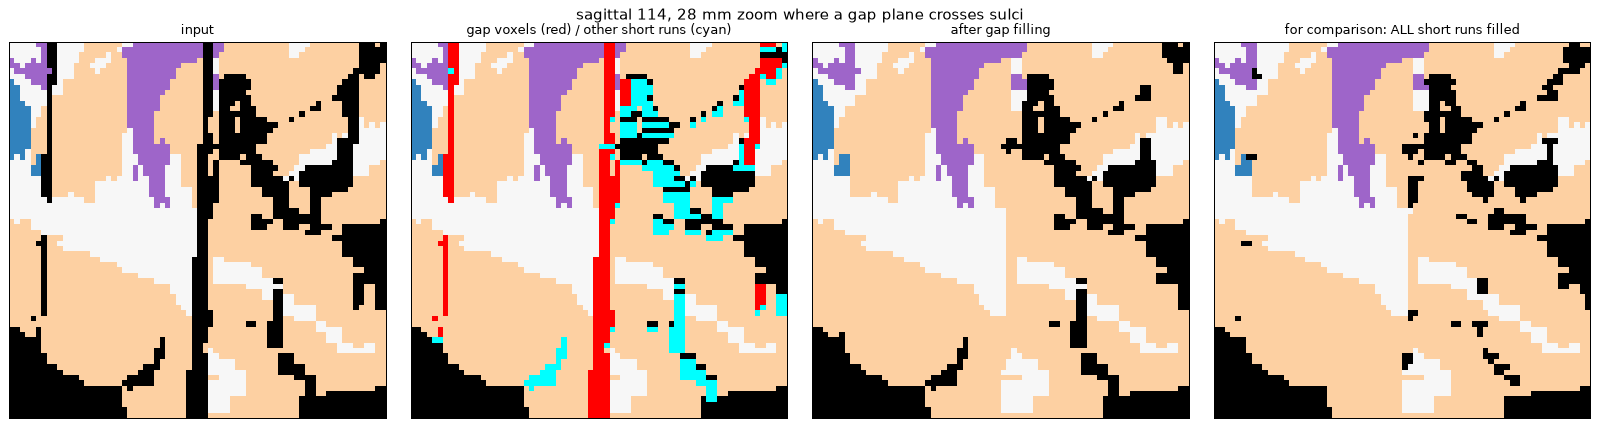

In [13]:
x = seg.copy()
if np.any(T):
    x, _ = R.apply_block_translations(x, bplanes, T, axis)
g = R.gap_voxels(x, planes, zooms, axis, 2.4)
x_gap = R.fill_nearest(x, g)
naive_runs = R.fill_nearest(x, short)          # fill ALL short runs, no plane restriction
print(f"gap voxels: {g.sum():,} | filled with tissue: {((x_gap > 0) & g).sum():,} | kept as background (sulci crossing): {((x_gap == 0) & g).sum():,}")

# zoom where a gap plane crosses sulci: window with most gap voxels AND most cortex-lined short runs
H = 35
best = (-1, None)
gs, ss = g[MID[0]], (cx_run & ~g)[MID[0]]                  # (j, z) planes of the sagittal slice
for p in planes:
    for zc in range(H, seg.shape[2] - H, 5):
        jc = int(p["coef"][0] * MID[0] + p["coef"][1] * zc + p["coef"][2])
        if not H <= jc < seg.shape[1] - H: continue
        w = (slice(jc - H, jc + H), slice(zc - H, zc + H))
        sc_ = min(gs[w].sum(), ss[w].sum())
        if sc_ > best[0]: best = (sc_, (zc, jc))
zc, jc = best[1]
cr = crop_at(zc, jc, H)
fig, axs = plt.subplots(1, 4, figsize=(18, 4.8))
show_l1(axs[0], lut[x], SAG, MID[0], cr, "input")
show_l1(axs[1], lut[x], SAG, MID[0], cr, "gap voxels (red) / other short runs (cyan)")
overlay(axs[1], short & ~g, SAG, MID[0], "cyan", cr); overlay(axs[1], g, SAG, MID[0], "red", cr)
show_l1(axs[2], lut[x_gap], SAG, MID[0], cr, "after gap filling")
show_l1(axs[3], lut[naive_runs], SAG, MID[0], cr, "for comparison: ALL short runs filled")
plt.suptitle(f"sagittal {MID[0]}, {2 * H * zooms[0]:.0f} mm zoom where a gap plane crosses sulci"); plt.tight_layout(); plt.show()

## 7. Step 4: cracks (`crack_voxels`)

Some missing tissue is not on a block boundary: thin cracks inside a block, or gaps the plane
detection missed. A crack voxel is a background voxel in a run ≤ `max_crack_mm` (1 mm) along **any**
of the three axes, bounded at both ends by the **same non-cortical class** (e.g. white matter on both
sides).

**Why "same class" and "non-cortical"?**
- A sulcus is bounded by cortex, so it never qualifies.
- A thin background sheet *between two different tissues* (e.g. WM | background | ventricle CSF) may be
  a real boundary in the original segmentation, so it is left alone. A sheet inside a single tissue
  (WM | background | WM) can only be an artefact.

**Why only ≤ 1 mm?** Longer runs inside white matter are rarer and may be real cavities (handled by
step 5 with stricter rules). The step is repeated `crack_iters` (2) times, because filling one crack
can make a neighbouring run short enough to qualify. Voxels are again filled with the nearest label.

crack voxels: iteration 1 39,709, iteration 2 9,334


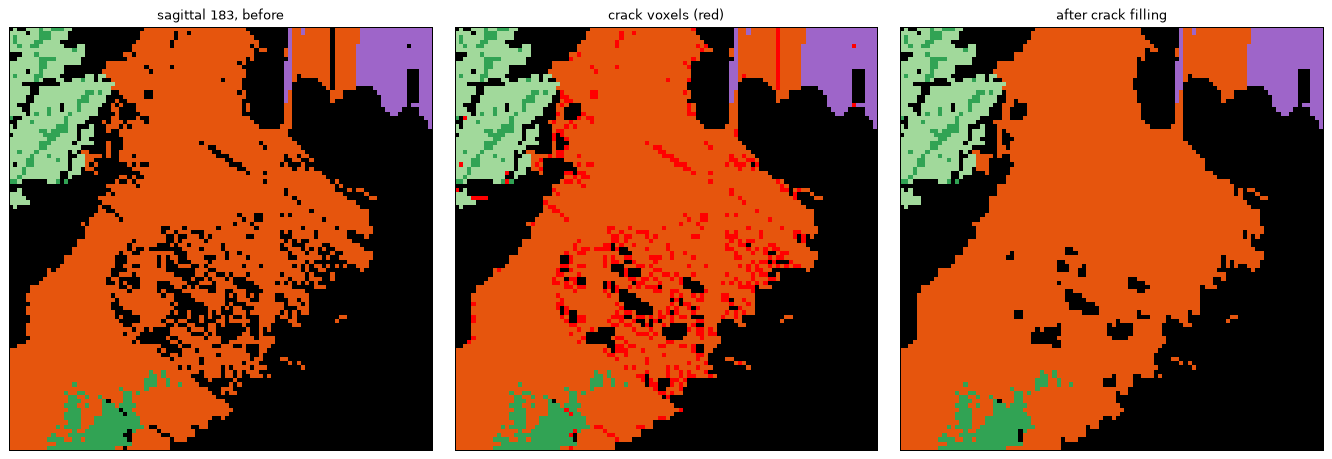

In [14]:
c = R.crack_voxels(x_gap, lut, zooms, 1.0)
x_cr = R.fill_nearest(x_gap, c, margin=3)
c2 = R.crack_voxels(x_cr, lut, zooms, 1.0)
x_cr = R.fill_nearest(x_cr, c2, margin=3)
print(f"crack voxels: iteration 1 {c.sum():,}, iteration 2 {c2.sum():,}")

# slice with the most crack voxels
xs = int(np.argmax(c.sum(axis=(1, 2))))
yz = np.argwhere(c[xs]); rc, cc = int(np.median(yz[:, 1])), int(np.median(yz[:, 0]))
cr = crop_at(rc, cc, 50)
other = (seg == 0) & ~c
fig, axs = plt.subplots(1, 3, figsize=(15, 5))
show_l1(axs[0], lut[x_gap], SAG, xs, cr, f"sagittal {xs}, before")
show_l1(axs[1], lut[x_gap], SAG, xs, cr, "crack voxels (red)")
overlay(axs[1], c, SAG, xs, "red", cr)
show_l1(axs[2], lut[x_cr], SAG, xs, cr, "after crack filling")
plt.tight_layout(); plt.show()

## 8. Step 5: enclosed holes (`hole_voxels`)

Larger holes are found as connected components of background that are **not connected to the
outside** (they don't touch the volume border). For each component, the tissue voxels on its border
are counted by class. The component is filled only if:
- at most `hole_max_cortex_frac` (30%) of its border is cortex, because a cavity lined by cortex is
  probably a sulcus closed off at both ends, and
- at most `hole_max_csf_frac` (2%) of its border is CSF.

**Why the CSF rule?** In NextBrain, most of the **lateral ventricle is unlabelled background**: only a
thin layer of CSF label lines it. Without this rule, the ventricle would be filled with white matter.
Real holes inside tissue rarely touch CSF.

**Why not fill all enclosed background (like `binary_fill_holes`)?** Many sulci become "enclosed" once
the gaps are filled, and the ventricles are enclosed too. The border composition is what tells them apart.

enclosed background: 90,541 vox | filled: 882 | kept because of cortex: 45,934 | kept because of CSF (ventricle): 43,725


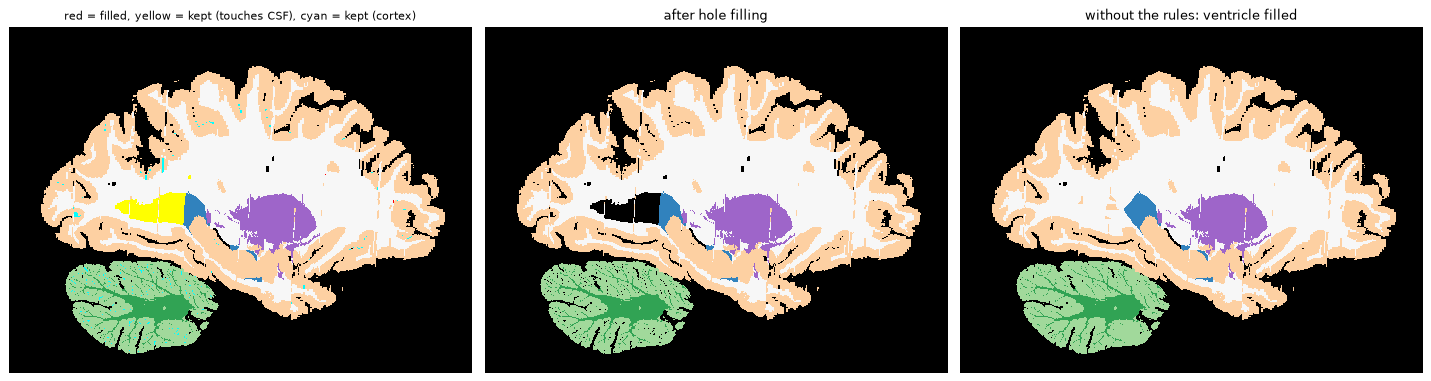

In [15]:
h = R.hole_voxels(x_cr, lut, max_cortex_frac=0.3, max_csf_frac=0.02)
h_all = R.hole_voxels(x_cr, lut, max_cortex_frac=1.0, max_csf_frac=1.0)    # every enclosed component
h_csf = R.hole_voxels(x_cr, lut, max_cortex_frac=0.3, max_csf_frac=1.0) & ~h   # rejected only by the CSF rule
x_h = R.fill_nearest(x_cr, h)
print(f"enclosed background: {h_all.sum():,} vox | filled: {h.sum():,} | "
      f"kept because of cortex: {(h_all & ~h & ~h_csf).sum():,} | kept because of CSF (ventricle): {h_csf.sum():,}")

xs = int(np.argmax(h_csf.sum(axis=(1, 2)))) if h_csf.any() else MID[0]
fig, axs = plt.subplots(1, 3, figsize=(16, 5))
show_l1(axs[0], lut[x_cr], SAG, xs, None, f"sagittal {xs}: enclosed background")
overlay(axs[0], h, SAG, xs, "red"); overlay(axs[0], h_csf, SAG, xs, "yellow"); overlay(axs[0], h_all & ~h & ~h_csf, SAG, xs, "cyan")
axs[0].set_title("red = filled, yellow = kept (touches CSF), cyan = kept (cortex)", fontsize=9)
show_l1(axs[1], lut[x_h], SAG, xs, None, "after hole filling")
show_l1(axs[2], lut[R.fill_nearest(x_cr, h_all)], SAG, xs, None, "without the rules: ventricle filled")
plt.tight_layout(); plt.show()

## 9. The full pipeline in one call

`restore_array` runs steps 1–5 in order (plane detection → shifts → gaps → cracks → holes) and also
returns a **step map** with the step that changed each voxel (1 gap, 2 crack, 3 hole, 4 shift) and a
**report** (planes, misalignments, voxel counts). `restore_nifti` / the CLI wrap it for files.

**Why this order?**
- Planes are detected on the raw input, where the gaps are still visible.
- Shifts are corrected **before** filling, so the gaps are filled from correctly aligned neighbours.
- Gaps before cracks: the plane-based rule is the most specific one; cracks catch what is left.
- Holes last: filling gaps and cracks closes some components, and the hole rule only has to judge
  what remains enclosed.

The result should be identical to the step-by-step version above:

23 s | identical to the step-by-step result: True
{'gap_voxels': 350932, 'gap_filled': 301158, 'crack_filled': 37390, 'hole_filled': 882, 'changed_voxels': 1054910}
planes: 14 | block translations: [[0, 0], [0, 0], [1, 0], [0, 0], [0, -2], [0, -1], [0, 1], [0, 0], [0, 1], [0, 0], [0, 0], [0, 1], [0, 0]]


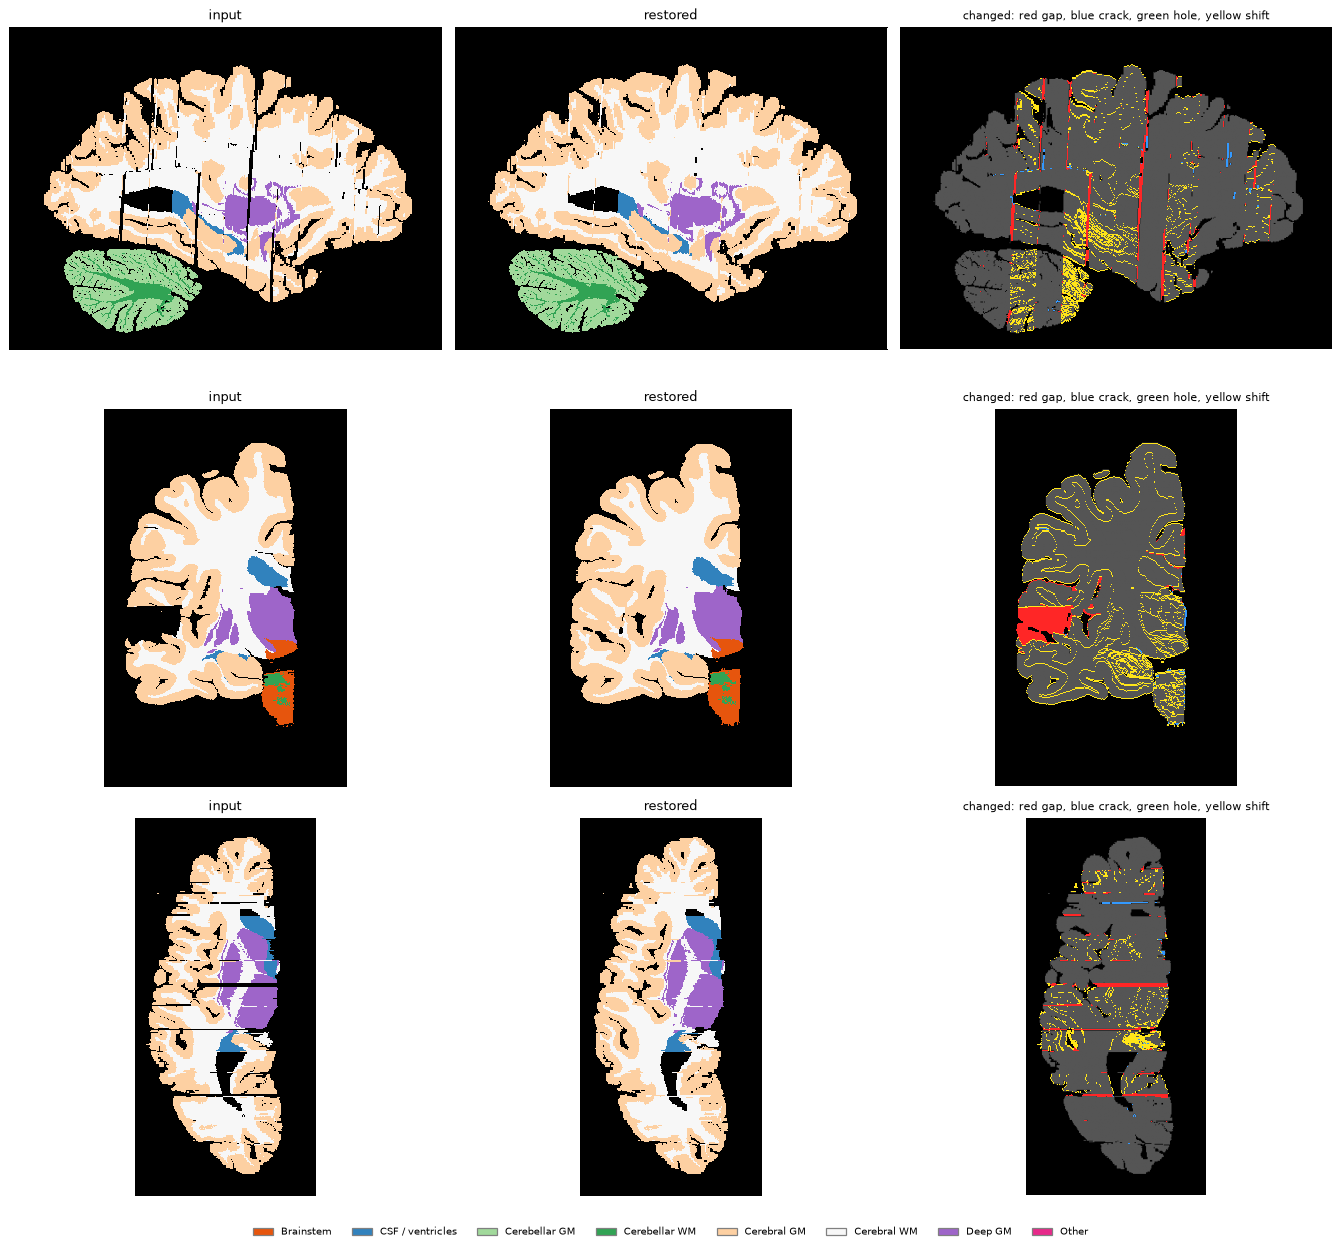

In [16]:
t0 = time.time()
restored, steps, rep = R.restore_array(seg, zooms, lut, affine, verbose=False)
print(f"{time.time() - t0:.0f} s | identical to the step-by-step result: {np.array_equal(restored, x_h)}")
print({k: rep[k] for k in ("gap_voxels", "gap_filled", "crack_filled", "hole_filled", "changed_voxels")})
print("planes:", len(rep["planes"]), "| block translations:", rep["block_translations_vox"])

STEP_CMAP = ListedColormap([(0, 0, 0, 0), (1, .15, .15, 1), (.2, .6, 1, 1), (.2, 1, .3, 1), (1, .9, .1, 1)])
fig, axs = plt.subplots(3, 3, figsize=(15, 14))
for r, (ax_i, idx) in enumerate(((SAG, MID[0]), (COR, MID[1]), (AXI, MID[2]))):
    show_l1(axs[r, 0], l1, ax_i, idx, title="input")
    show_l1(axs[r, 1], lut[restored], ax_i, idx, title="restored")
    axs[r, 2].imshow(sl(seg > 0, ax_i, idx), cmap="gray", vmin=0, vmax=3, origin="lower")
    axs[r, 2].imshow(sl(steps, ax_i, idx), cmap=STEP_CMAP, vmin=0, vmax=4, origin="lower", interpolation="nearest")
    axs[r, 2].set_title("changed: red gap, blue crack, green hole, yellow shift", fontsize=9); axs[r, 2].axis("off")
legend(fig); plt.tight_layout(rect=(0, 0.03, 1, 1)); plt.show()

From the command line (full resolution, all ~300 labels kept):
```bash
python restore.py input.nii.gz output.nii.gz          # + output_steps.nii.gz, output_report.json
python restore.py input_L1.nii.gz output.nii.gz --input-is-l1
python restore.py input.nii.gz output.nii.gz --no-shifts --max-gap-mm 3
```

## 10. Parameters

All parameters are in `R.DEFAULTS` and are CLI flags (`--max-gap-mm`, `--no-shifts`, …).

| parameter | default | step | what it controls | change it when… |
|---|---|---|---|---|
| `axis` | auto | all | slicing axis (A-P from the affine) | the blocks were cut in another orientation |
| `max_gap_mm` | 2.4 | 1, 3 | longest run counted as a gap | gaps are wider (raise) or sulci get filled (lower) |
| `angle_max` | 25 | 1 | search range of the global tilt (deg) | cuts are more oblique |
| `peak_z` | 4.0 | 1 | peak threshold in robust SDs | planes are missed (lower) or false planes appear (raise) |
| `min_coverage` | 0.02 | 1 | minimum plane coverage of the brain | small partial gaps are missed (lower) |
| `max_dev_deg` | 10 | 1 | tilt of each plane vs the global normal | blocks are cut at very different angles |
| `min_noncortex` | 0.08 | 1 | min fraction of runs bounded by non-cortex | false planes in sulcal regions (raise) |
| `do_shifts` | True | 2 | block shift correction | – |
| `max_shift_mm` | 3.0 | 2 | largest shift searched | blocks are badly misaligned |
| `min_shift_mm` | 0.4 | 2 | smaller measured shifts are ignored | – |
| `shift_lambda` | 0.3 | 2 | penalty on block translations | shifts accumulate (raise) or are under-corrected (lower) |
| `do_gaps`, `all_axes` | True, False | 3 | gap filling; also search the 2 other axes | some blocks are cut in another orientation (see limitations) |
| `do_cracks`, `max_crack_mm`, `crack_iters` | True, 1.0, 2 | 4 | crack filling | – |
| `do_holes`, `hole_max_cortex_frac`, `hole_max_csf_frac` | True, 0.3, 0.02 | 5 | hole filling | ventricles get filled (lower CSF fraction) |

## 11. L1 inputs, validation and limitations

**L1 inputs.** Every rule only looks at the L1 class of a label, and every fill copies the label of a
voxel. So restoring the full-label image and converting the result to L1 gives exactly the same
result as restoring the L1 image with `--input-is-l1`. This was checked voxel for voxel on all 5
cases. Without `--input-is-l1`, an L1 image is read as raw NextBrain IDs and the classes are wrong.

**Validation** (`benchmark/`). Known synthetic gaps, block shifts, cracks and holes were added to clean
FOMO segmentations and to the real cases at 0.4 mm, and only the corrupted voxels were scored:

| | clean FOMO (4 hemispheres) | real cases as reference (5) |
|---|---|---|
| gap voxels fixed | 84–87% | 76–82% |
| shifted-block voxels fixed | 66–83% (2% without the shift step) | 58–71% |
| holes/cracks fixed | 38–58% | 22–45% |
| sulci closed on a clean volume | ≤ 0.1% | – |

The naive baseline (`baseline_naive.py`: close the brain outline and fill everything inside) fixes as many
gaps but closes 83–97% of the sulci.

**Limitations**
1. **Holes inside cortex** (~1% fixed): locally they look exactly like a sulcus, so no local rule can
   tell them apart. They need an anatomical prior (atlas or learned model).
2. **Gaps in other orientations** (e.g. blocks around the brainstem cut axially). `--all-axes` looks for
   them, but on secondary axes real and false planes can't be separated reliably, so it is off by default.
3. **Non-rigid misalignment**: one integer translation per block, no rotation or deformation. The
   cerebellum, cut separately in NextBrain, gets the translation of the cerebral block it lies in.
4. **Missed planes**: ~10–15% of synthetic gap planes are not detected (low coverage); their gaps
   are partly caught by the crack step, the rest stay open.